# Optimal BB84 Probe

Note the conventions used in this notebook 

- `a` is Alice's signal, which passes through to Bob
- `e`, `f` is Eve's two-qubit probe, which she stores until Alice announces the basis
- `x`, `y` is the rectilinear $\ket{0}$ and $\ket{1}$ basis via `Z` gate
- `u`, `v` is the diagonal $\ket{+}$ and $\ket{-}$ basis via `X` gate

The tensor is `(f, e, a)`, putting `a` on the top of diagrams.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from qutip import basis, tensor, ket2dm, qeye, sigmaz, entropy_vn
from qutip_qip.circuit import QubitCircuit
from qutip_qip.operations import gate_sequence_product

In [5]:
x, y = basis(2, 0), basis(2, 1)
u, v = (x + y).unit(), (x - y).unit()

F, E, A = 0, 1, 2                    # qubit indices in the tensor order (f, e, a)
WIRES = ["", "", "f", "e", "a"]      # wire labels, bottom to top

The circuit without the noisy channel is given below.

In [73]:
def build_circuit(noisy):
    qc = QubitCircuit(3)
    qc.add_gate("CNOT", controls=A, targets=E)    # gate 1: a -> e
    qc.add_gate("CNOT", controls=F, targets=A)    # gate 2: f -> a
    if noisy:
        qc.add_gate(r"$\mathcal{N}_\lambda$", targets=E)
        qc.add_gate(r"$\mathcal{N}_\lambda$", targets=F)
            
    return qc

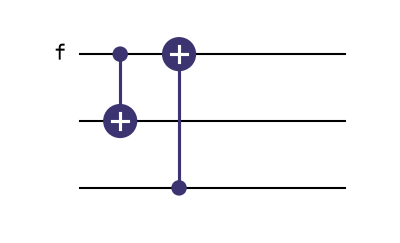

In [75]:
build_circuit(noisy=False).draw("matplotlib", wire_label=WIRES)

We can run the usual BB84 protocol and compair it with this to see the different QBERs.

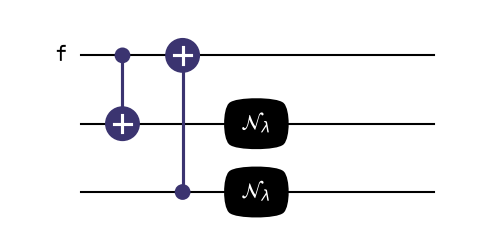

In [78]:
build_circuit(noisy=True).draw("matplotlib", wire_label=WIRES)

Eve picks the error rate $D$ she is willing to cause, then prepares

$$|e_0\rangle = \sqrt{1-\Delta}\,|x\rangle + \sqrt{\Delta}\,|y\rangle, \qquad
  |f_0\rangle = \sqrt{1-D}\,|x\rangle + \sqrt{D}\,|y\rangle, \qquad
  \Delta = \tfrac12 - \sqrt{D(1-D)}$$

In [51]:
def probe(D):
    Delta = 0.5 - np.sqrt(D * (1 - D))
    e0 = np.sqrt(1 - Delta) * x + np.sqrt(Delta) * y
    f0 = np.sqrt(1 - D)     * x + np.sqrt(D)     * y
    return e0, f0

running this gives ... 

## Running BB84:

In [55]:
BASES = {"Z": (x, y), "X": (u, v)}

def bb84_qber(circuit, signal, probe=None):
    U = gate_sequence_product(circuit.propagators())
    if probe is None:
        probe = [basis(2, 0)] * (circuit.N - 1) # |0> repeated N-1 times

    errors = {"Z": [], "X": []}

    for alice_basis in ["Z", "X"]:
        for bob_basis in ["Z", "X"]:

            if alice_basis != bob_basis:
                continue

            for bit in [0, 1]:                            
                sent     = alice_prepares(bit, alice_basis)
                received = eve_attacks(U, sent, signal, probe)
                p0, p1   = bob_measures(received, bob_basis)

                errors[alice_basis].append(p1 if bit == 0 else p0)

    Q_Z = float(np.mean(errors["Z"]))
    Q_X = float(np.mean(errors["X"]))
    return Q_Z, Q_X, (Q_Z + Q_X) / 2

For plane bb84 with no eve

In [58]:
bb84_qber(QubitCircuit(1), signal=0)

(0.0, 0.0, 0.0)

For bb84 with standard eve where they use a cnot to "copy" (not really but entangle with it) the state since if the input is 

In [61]:
copier = QubitCircuit(2)
copier.add_gate("CNOT", controls=1, targets=0)

bb84_qber(copier, signal=1)

(0.0, 0.49999999999999983, 0.24999999999999992)

BB84 with optimal Eve

In [80]:
e0, f0 = probe(0.10)

bb84_qber(build_circuit(noisy=False), signal=A, probe=[f0, e0])

(0.09999999999999999, 0.10000000000000003, 0.1)